# Analyse Exploratoire des Données (EDA) - Table Consolidée de Modélisation (version 4)

**Auteur** : Christian & Collaborateurs
**Date** : 03 novembre 2026
**Objectif** : Analyser le jeu de données final consolidé pour valider l'intégrité de nos variables (équipements, délinquance, démographie, taux) et guider nos choix d'ingénierie des caractéristiques (Feature Engineering) avant d'amorcer l'entraînement de nos modèles de Machine Learning.

## Ce qui change par rapport à la version 3 (02/11/2026)

La version 3 a été réalisée sur la table **avant** le correctif de la densité des arrondissements : la superficie de Paris, Lyon et Marseille était répartie entre leurs arrondissements au prorata de leur population, ce qui donnait à chaque arrondissement la densité de sa ville.

Cette version 4 analyse `table_modelisation_bv.parquet` **après** le correctif : les 45 arrondissements utilisent leur superficie réelle (source : geo.api.gouv.fr).

- Les sections 1 à 9 reprennent la structure et le code de la version 3. Les résultats qui ne dépendent pas de la densité sont inchangés et le sont explicitement vérifiés.
- La section 5 est complétée par une comparaison **avant / après** de la densité.
- Les sections 10 (densité de population), 11 (revue des variables explicatives) et 12 (synthèse) sont nouvelles.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique pour les présentations de l'équipe
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
pd.set_option("display.max_columns", None)

print("Packages chargés avec succès.")

Packages chargés avec succès.


## 1. Chargement et structure de la Table Consolidée

Nous importons le fichier exporté au format Parquet et vérifions ses dimensions.
Puisque le fichier utilise un index à 3 niveaux (annee, sous_bassin_de_vie, type_bien), nous l'inspectons avec attention sans dupliquer nos colonnes.

In [2]:
# Chemin relatif depuis le dossier '02_audit_eda'
chemin_parquet = Path("../data/processed/table_modelisation_bv.parquet")

if not chemin_parquet.exists():
    raise FileNotFoundError(f"Le fichier est introuvable à l'emplacement : {chemin_parquet.resolve()}")

df = pd.read_parquet(chemin_parquet)

print(f"Structure de la table validée.")
print(f"-> Nombre de lignes (observations) : {df.shape[0]}")
print(f"-> Nombre de colonnes (caractéristiques) : {df.shape[1]}")

# Affichage des niveaux de l'index pour rassurer l'équipe
print(f"-> Niveaux de l'index détectés : {list(df.index.names)}")

# Contrôles complémentaires (version 4)
print(f"-> Index unique : {df.index.is_unique}")
annees = df.index.get_level_values('annee')
print(f"-> Période : {annees.min()} - {annees.max()}")
print(f"-> Sous-bassins de vie distincts : {df.index.get_level_values('sous_bassin_de_vie').nunique()}")
print("-> Lignes par type de bien :", df.index.get_level_values('type_bien').value_counts().to_dict())

Structure de la table validée.
-> Nombre de lignes (observations) : 28450
-> Nombre de colonnes (caractéristiques) : 38
-> Niveaux de l'index détectés : ['annee', 'sous_bassin_de_vie', 'type_bien']
-> Index unique : True
-> Période : 2015 - 2025
-> Sous-bassins de vie distincts : 1811
-> Lignes par type de bien : {'maison': 19559, 'appartement': 8891}


**Lecture.** La structure est identique à celle de la version 3 : 28 450 lignes × 38 colonnes, index à 3 niveaux unique. Le correctif de densité modifie des **valeurs** (la colonne `densite_population` de 45 sous-bassins), pas la **forme** de la table.

## 2. Audit de Complétude et Types de Données

Il est critique de recenser les valeurs manquantes (NaN) héritées des jointures (comme Filosofi ou la BPE).
Certains algorithmes de Machine Learning ne gèrent pas nativement les données manquantes et cet audit guidera nos futures stratégies d'imputation.

In [3]:
# Étape 1 : Analyse rapide des formats de colonnes
print("--- Types des variables ---")
print(df.dtypes.value_counts())

# Étape 2 : Calcul du taux de complétude
manquants = df.isna().sum()
taux_manquants = (manquants / len(df)) * 100

df_manquants = pd.DataFrame({
    'Total Manquants': manquants,
    'Taux (%)': taux_manquants
}).sort_values(by='Taux (%)', ascending=False)

# On filtre pour n'afficher que les colonnes ayant des données manquantes
colonnes_avec_nan = df_manquants[df_manquants['Total Manquants'] > 0]

if len(colonnes_avec_nan) == 0:
    print("\nFélicitations ! Aucune valeur manquante détectée dans la table finale.")
else:
    print(f"\nVariables contenant des NaNs à traiter ({len(colonnes_avec_nan)} colonnes) :")
    print(colonnes_avec_nan)

--- Types des variables ---
float64    35
int64       3
Name: count, dtype: int64

Variables contenant des NaNs à traiter (11 colonnes) :
                                 Total Manquants   Taux (%)
part_indicateurs_estimes                    4952  17.405975
taux3_destructions                          4952  17.405975
taux3_cambriolages                          4952  17.405975
taux3_vols_sans_violence                    4952  17.405975
taux3_vols_violents                         4952  17.405975
taux3_vols_vehicules                        4952  17.405975
taux3_violences_intrafamiliales             4952  17.405975
taux3_stupefiants                           4952  17.405975
taux3_violences_sexuelles                   4952  17.405975
taux_vacance_complete                         11   0.038664
part_logements_taux_impute                    11   0.038664


**Lecture.** Résultat identique à la version 3 : 11 colonnes contiennent des valeurs manquantes. Les 9 variables de délinquance (8 taux + `part_indicateurs_estimes`) sont vides sur 4 952 lignes (17,4 %), `taux_vacance_complete` et `part_logements_taux_impute` sur 11 lignes (0,04 %). **`densite_population` est complète** : aucun sous-bassin sans densité.

## 3. Extraction sécurisée de l'Index Temporel et Métier

Pour éviter l'erreur de compilation classique sous Pandas (`ValueError: cannot insert annee, already exists`), nous allons extraire les variables temporelles (`annee`) et la typologie du bien (`type_bien`) de notre index pour les injecter sous de nouveaux noms de variables réservés aux graphiques.

In [4]:
# Copie de sécurité pour travailler sans altérer le jeu de données original
df_plot = df.copy()

# Extraction des index en colonnes avec des noms uniques pour éviter tout conflit
df_plot['annee_graphique'] = df_plot.index.get_level_values('annee')
df_plot['type_bien_graphique'] = df_plot.index.get_level_values('type_bien')

print("Index dupliqués et renommés en colonnes de travail avec succès.")

Index dupliqués et renommés en colonnes de travail avec succès.


## 4. Analyse de la Distribution des Volumes de Transactions

Nous traçons des diagrammes en boîte (Boxplots) pour visualiser la distribution des ventes à travers le temps.
Cette vue permet de confirmer deux éléments cruciaux : la tendance baissière globale du marché immobilier récent et la présence d'outliers géographiques (grands bassins à forts volumes).

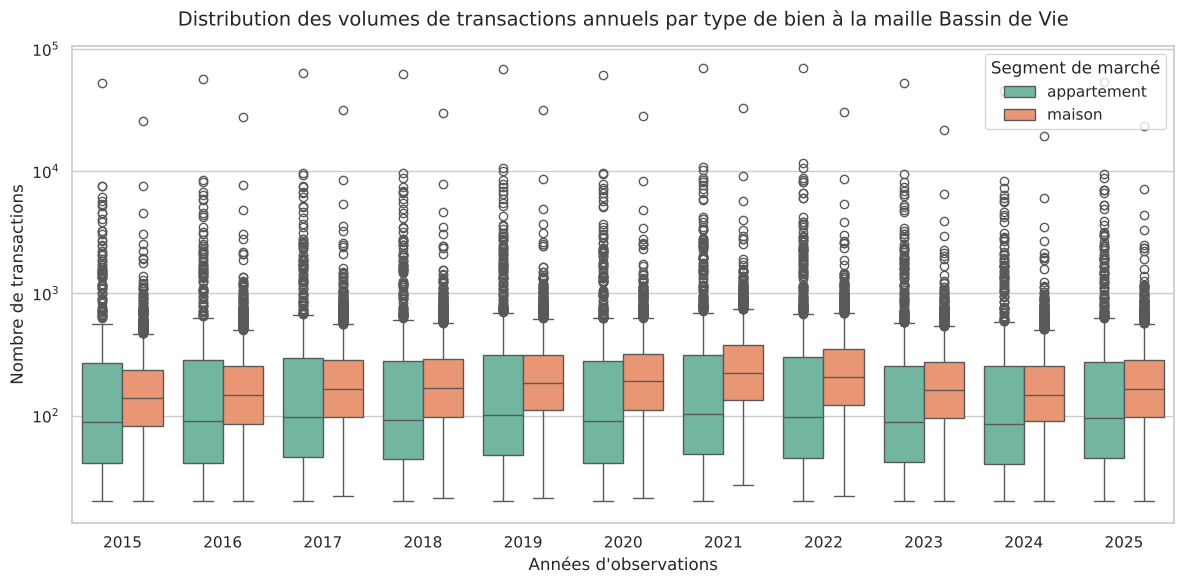

In [5]:
plt.figure(figsize=(12, 6))

# Boxplot du nombre de ventes en filtrant pour éviter les croisements aberrants
sns.boxplot(
    data=df_plot,
    x="annee_graphique",
    y="n_ventes",
    hue="type_bien_graphique",
    palette="Set2"
)

plt.title("Distribution des volumes de transactions annuels par type de bien à la maille Bassin de Vie", pad=15)
plt.xlabel("Années d'observations")
plt.ylabel("Nombre de transactions")
plt.legend(title="Segment de marché")
plt.yscale("log") # Utilisation de l'échelle logarithmique en cas d'outliers extrêmes
plt.tight_layout()
plt.show()

### Interprétation

Le graphique présente la distribution du nombre annuel de transactions immobilières par bassin de vie, en distinguant les maisons et les appartements, sur la période 2015-2025. Ces volumes ne dépendent pas du correctif de densité : les constats de la version 3 sont confirmés.

- **Des volumes médians généralement plus élevés pour les maisons** : sur toutes les années, le nombre médian de transactions par bassin de vie est supérieur pour les maisons à celui des appartements (par exemple 166 contre 95 en 2025).
- **Une évolution temporelle différente selon le type de bien** : pour les maisons, le volume médian progresse entre 2015 (139) et 2021 (225), diminue entre 2022 et 2024 (148), puis remonte en 2025 (166). Pour les appartements, la distribution reste plus stable (médiane entre 85 et 104 selon les années).
- **Une forte dispersion des volumes** : certains territoires enregistrent beaucoup plus de transactions que la majorité, ce qui se traduit par un nombre élevé de valeurs atypiques.
- **La présence de valeurs extrêmes** : certains bassins atteignent des volumes très élevés (jusqu'à 70 042 transactions pour un appartement). L'échelle logarithmique rend ces écarts visibles sans écraser les distributions des territoires moins actifs.

**Conclusion** : les bassins de vie ayant des volumes de transactions très faibles peuvent présenter des prix moins représentatifs et plus sensibles à quelques ventes atypiques. Le seuil de 20 ventes minimum appliqué dans la table limite ce risque sans le supprimer.

## 5. Statistiques Descriptives Segmentées

Le marché des appartements et celui des maisons répondent à des dynamiques économiques différentes.
Nous extrayons les résumés statistiques (`describe`) pour chacun de ces deux segments indépendamment.

In [6]:
print("=== MARCHÉ EXCLUSIF DES MAISONS ===")
df_maisons = df_plot[df_plot['type_bien_graphique'] == 'maison']
display(df_maisons[['n_ventes', 'prix', 'densite_population']].describe().T)

print("\n=== MARCHÉ EXCLUSIF DES APPARTEMENTS ===")
df_apparts = df_plot[df_plot['type_bien_graphique'] == 'appartement']
display(df_apparts[['n_ventes', 'prix', 'densite_population']].describe().T)

=== MARCHÉ EXCLUSIF DES MAISONS ===


,count,mean,std,min,25%,50%,75%,max
n_ventes,19559.0,264.854645,733.230522,20.00000,100.000000,172.000000,296.000000,32970.000000
prix,19559.0,1972.593589,1090.644771,350.00000,1269.000000,1702.000000,2367.000000,19652.000000
densite_population,19559.0,256.773394,999.220024,5.59383,39.451724,73.987382,154.011111,30874.676895



=== MARCHÉ EXCLUSIF DES APPARTEMENTS ===


,count,mean,std,min,25%,50%,75%,max
n_ventes,8891.0,428.499606,2289.207098,20.00000,44.000000,95.000000,286.000000,70042.000000
prix,8891.0,2523.136880,1733.068033,470.00000,1481.000000,2118.000000,3007.500000,14967.000000
densite_population,8891.0,1161.817158,4144.549661,5.59383,67.907688,134.413333,342.863636,37873.471849


### 5 bis. Densité de population : comparaison avant / après le correctif

Le tableau ci-dessous compare les statistiques de `densite_population` de la **version 3** (valeurs reprises de l'EDA du 02/11/2026, réalisée avant le correctif) à celles de la table actuelle.

In [7]:
# Valeurs de la version 3 de l'EDA (02/11/2026), table AVANT correctif (prorata)
avant = pd.DataFrame({
    'maison':      {'mean': 243.758011, 'std': 816.480911, '25%': 39.451724, '50%': 73.987382, '75%': 154.011111, 'max': 20035.980952},
    'appartement': {'mean': 1001.066643, 'std': 3303.431066, '25%': 67.907688, '50%': 134.413333, '75%': 342.863636, 'max': 20035.980952},
}).T

stats_apres = (df_plot.groupby('type_bien_graphique')['densite_population']
               .describe()[['mean', 'std', '25%', '50%', '75%', 'max']])

comparaison = pd.concat({'avant (v3)': avant, 'après (v4)': stats_apres}, axis=1)
display(comparaison.round(1))

variation = ((stats_apres / avant - 1) * 100).round(1)
print("Variation en % (après / avant) :")
display(variation)

avant (v3)                                      après (v4)  \
                  mean     std   25%    50%    75%      max       mean   
maison           243.8   816.5  39.5   74.0  154.0  20036.0      256.8   
appartement     1001.1  3303.4  67.9  134.4  342.9  20036.0     1161.8   

                                                  
                std   25%    50%    75%      max  
maison        999.2  39.5   74.0  154.0  30874.7  
appartement  4144.5  67.9  134.4  342.9  37873.5

Variation en % (après / avant) :


,mean,std,25%,50%,75%,max
type_bien_graphique,,,,,,
appartement,16.1,25.5,0.0,0.0,0.0,89.0
maison,5.3,22.4,0.0,-0.0,0.0,54.1


**Lecture.** Le correctif ne modifie **que la queue haute** de la distribution :

- Les quartiles (25 %, 50 %, 75 %) sont **strictement inchangés** pour les deux segments (par exemple médiane des maisons : 74 hab/km², 75 % des appartements : 343 hab/km²). Les 45 arrondissements sont une très petite part de la table.
- Le **maximum** passe de 20 036 à **30 875** pour les maisons et à **37 873** pour les appartements : l'arrondissement le plus dense (Paris 11e) est près de deux fois plus dense que la valeur uniforme précédemment attribuée à tout Paris.
- La **moyenne et l'écart-type** des appartements augmentent (+16 % et +25 %) : la dispersion augmente nettement.

Avant le correctif, le maximum de 20 036 correspondait vraisemblablement à la valeur uniforme appliquée aux arrondissements parisiens. Le gain de réalisme se paie par une asymétrie plus forte, traitée en section 10.

## 6. Analyse des Corrélations Linéaires (Marché des Maisons)

Pour clore cette première approche d'EDA, nous traçons une carte thermique (Heatmap) des corrélations de Pearson.
Pour conserver une lisibilité optimale pour l'équipe, nous isolons notre cible et y ajoutons les indicateurs de criminalité et d'équipements numériques de notre choix.

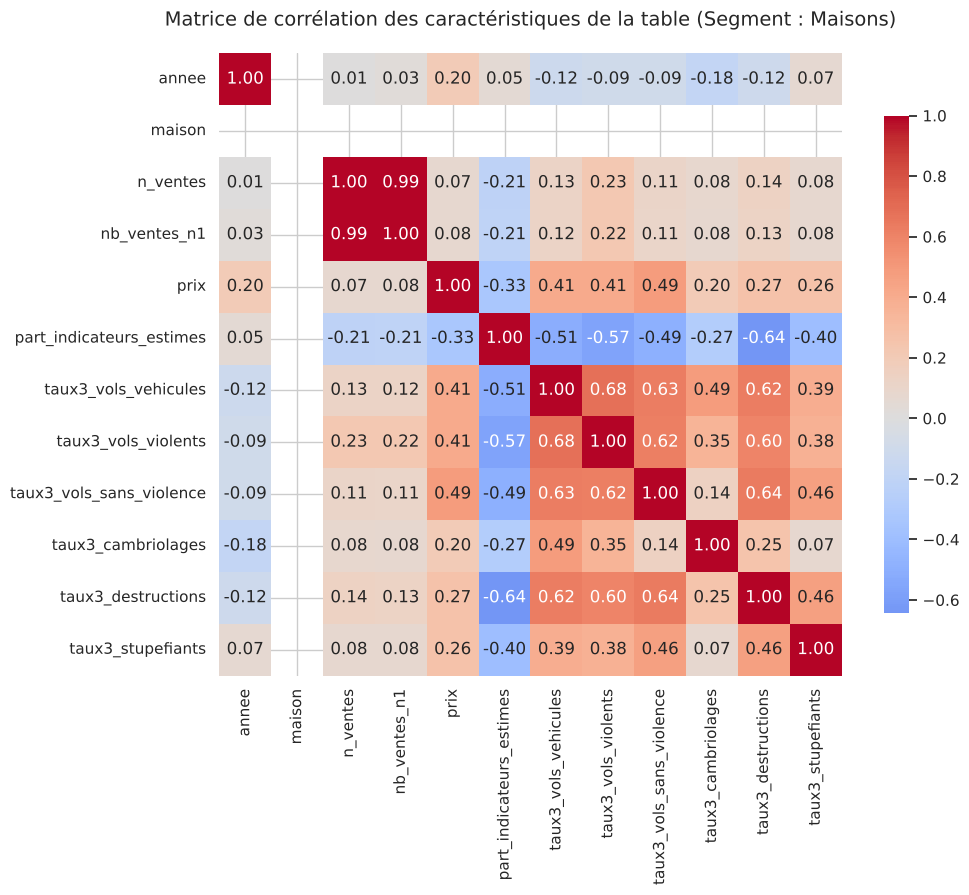

In [8]:
# Sélection automatique des 12 premières colonnes numériques de la table
colonnes_numeriques = [c for c in df_maisons.columns if df_maisons[c].dtype in [np.float64, np.int64]]
selection_features = colonnes_numeriques[:12]

# Calcul de la matrice de corrélation
matrice_corr = df_maisons[selection_features].corr()

# Affichage graphique
plt.figure(figsize=(11, 9))
sns.heatmap(
    matrice_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    cbar_kws={"shrink": .8}
)
plt.title("Matrice de corrélation des caractéristiques de la table (Segment : Maisons)", pad=20)
plt.tight_layout()
plt.show()

### Interprétation

La matrice de corrélation permet d'observer les relations linéaires entre le prix des maisons et les autres variables quantitatives. Elle porte sur les 12 premières colonnes numériques, **qui ne contiennent pas la densité** : ses résultats sont donc identiques à ceux de la version 3. La colonne `maison` apparaît vide (constante égale à 1 dans ce segment, corrélation non définie).

- **Une corrélation positive entre le prix et certains indicateurs de sécurité** : vols sans violence (0,49), vols de véhicules (0,41), vols violents (0,41), destructions (0,27), stupéfiants (0,26) et cambriolages (0,20). Ces résultats sont contre-intuitifs si l'on suppose qu'une hausse de la délinquance est associée à une baisse des prix. Ils peuvent refléter des différences entre territoires : les zones urbaines ou touristiques cumulent des prix élevés et davantage de faits enregistrés.
- **Une corrélation négative entre le prix et la part d'indicateurs estimés** (-0,33) : les bassins où cette part est plus élevée présentent des prix de maisons plus faibles, ce qui peut traduire des différences de couverture ou de qualité des données selon les territoires.
- **Une faible corrélation entre le prix et le nombre de ventes** : 0,07 pour `n_ventes`.
- **Une corrélation positive modérée entre l'année et le prix** (0,20) : tendance générale à la hausse des prix.
- **Une forte corrélation entre `n_ventes` et `nb_ventes_n1`** (0,99) : les ventes de l'année N et de l'année N-1 évoluent presque identiquement. `n_ventes` est exclue des variables explicatives (fuite), mais `nb_ventes_n1` est conservée.
- **Des corrélations importantes entre les indicateurs de sécurité** (par exemple vols de véhicules et vols violents).

**Conclusion** : les corrélations observées ne permettent pas de conclure à des relations de causalité. Cette matrice porte uniquement sur le segment des maisons ; la section 11 complète l'analyse pour les deux segments et pour toutes les variables, y compris la densité.

## 7. Analyse temporelle du prix au m²

L'objectif de cette analyse est d'étudier l'évolution de notre variable cible : le prix au m².
Nous cherchons à déterminer si les prix suivent une tendance particulière au fil des années et si cette évolution diffère entre les maisons et les appartements.
Cette analyse doit notamment permettre d'évaluer l'intérêt de prendre en compte la dimension temporelle dans l'explication des prix immobiliers.
Le volume des transactions sera également observé, mais uniquement comme indicateur complémentaire permettant de contextualiser l'activité du marché.

In [9]:
# Agrégation des prix et des volumes par année et type de bien
evolution_prix = (
    df_plot
    .dropna(subset=["prix", "annee_graphique"])
    .groupby(["annee_graphique", "type_bien_graphique"])
    .agg(
        prix_median=("prix", "median"),
        prix_moyen=("prix", "mean"),
        nombre_observations=("prix", "count"),
        volume_ventes=("n_ventes", "sum")
    )
    .reset_index()
    .sort_values("annee_graphique")
)

display(evolution_prix.round(2))

,annee_graphique,type_bien_graphique,prix_median,prix_moyen,nombre_observations,volume_ventes
0,2015,appartement,1920.0,2249.12,691,277055
1,2015,maison,1495.0,1687.25,1769,387202
2,2016,appartement,1922.0,2240.26,717,297192
3,2016,maison,1500.0,1699.93,1775,412587
4,2017,appartement,1930.0,2268.50,746,341671
5,2017,maison,1533.0,1731.05,1776,468682
6,2018,appartement,1920.0,2294.83,774,341210
7,2018,maison,1569.0,1781.98,1780,468051
8,2019,appartement,1953.0,2347.04,805,381256
9,2019,maison,1583.5,1827.90,1780,513595


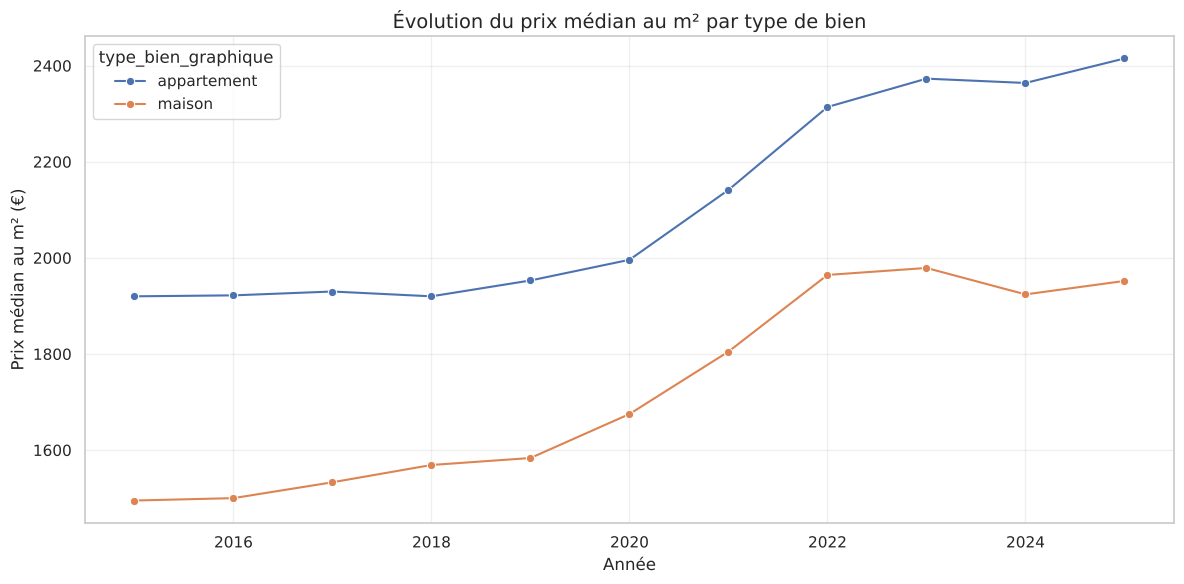

In [10]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=evolution_prix,
    x="annee_graphique",
    y="prix_median",
    hue="type_bien_graphique",
    marker="o"
)

plt.title("Évolution du prix médian au m² par type de bien")
plt.xlabel("Année")
plt.ylabel("Prix médian au m² (€)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

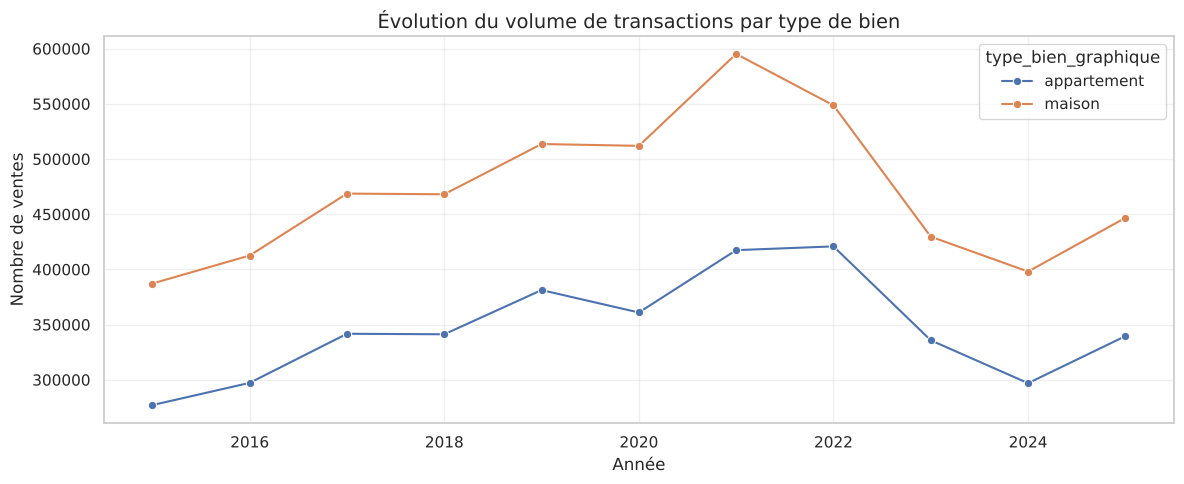

In [11]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=evolution_prix,
    x="annee_graphique",
    y="volume_ventes",
    hue="type_bien_graphique",
    marker="o"
)

plt.title("Évolution du volume de transactions par type de bien")
plt.xlabel("Année")
plt.ylabel("Nombre de ventes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation des résultats

L'évolution du prix médian au m² montre une tendance globalement haussière entre 2015 et 2025, aussi bien pour les maisons que pour les appartements. Ces résultats portent sur la variable cible et sont identiques à ceux de la version 3.

- Les appartements présentent les niveaux de prix les plus élevés sur toute la période : de 1 920 €/m² en 2015 à 2 415 €/m² en 2025 (environ +26 %).
- Pour les maisons, le prix médian passe de 1 495 €/m² en 2015 à 1 952 €/m² en 2025 (environ +31 %).
- La progression s'accélère à partir de 2020-2021, puis une légère inflexion apparaît pour les maisons en 2024, tandis que les appartements se stabilisent avant une nouvelle progression en 2025.
- Le prix moyen est systématiquement supérieur au prix médian : la distribution des prix est asymétrique, avec des territoires à valeurs particulièrement élevées.
- Le volume des transactions progresse jusqu'en 2021 pour les deux catégories, diminue nettement en 2023 et 2024, puis reprend partiellement en 2025.

**Enjeu pour le projet** : la dimension temporelle est importante pour comprendre les variations du prix au m². L'année (ou, mieux, le prix de l'année précédente `prix_n1`) doit être examinée comme variable explicative.

## 8. Analyse des disparités territoriales des prix

Le prix au m² peut varier sensiblement d'un sous-bassin de vie à un autre.
Cette analyse vise à identifier les territoires présentant les niveaux de prix les plus élevés et les plus faibles, en distinguant les maisons des appartements.
Pour garantir la comparabilité, nous retenons la dernière année disponible dans le jeu de données.
Nous associons également le volume de transactions à chaque territoire afin de contextualiser les prix observés.

In [12]:
# Copie de travail
df_territoires = df_plot.copy()

# Extraction du sous-bassin de vie depuis l'index
df_territoires["sous_bassin_graphique"] = (
    df_territoires.index.get_level_values("sous_bassin_de_vie")
)

# Identification de la dernière année disponible
derniere_annee = df_territoires["annee_graphique"].max()
print("Dernière année disponible :", derniere_annee)

# Filtrage sur la dernière année
df_territoires_recent = df_territoires[
    df_territoires["annee_graphique"] == derniere_annee
].copy()

# Agrégation territoriale
analyse_territoriale = (
    df_territoires_recent
    .groupby(["type_bien_graphique", "sous_bassin_graphique"])
    .agg(
        prix_median=("prix", "median"),
        prix_moyen=("prix", "mean"),
        volume_ventes=("n_ventes", "sum"),
        nombre_observations=("prix", "count")
    )
    .reset_index()
)

display(analyse_territoriale.head(10))

Dernière année disponible : 2025


,type_bien_graphique,sous_bassin_graphique,prix_median,prix_moyen,volume_ventes,nombre_observations
0,appartement,01004,2329.0,2329.0,150,1
1,appartement,01033,2343.0,2343.0,204,1
2,appartement,01034,1987.0,1987.0,62,1
3,appartement,01053,1846.0,1846.0,470,1
4,appartement,01093,2375.0,2375.0,46,1
5,appartement,01138,2028.0,2028.0,22,1
6,appartement,01143,5903.0,5903.0,169,1
7,appartement,01160,5000.0,5000.0,296,1
8,appartement,01173,4643.0,4643.0,315,1
9,appartement,01202,1984.0,1984.0,34,1


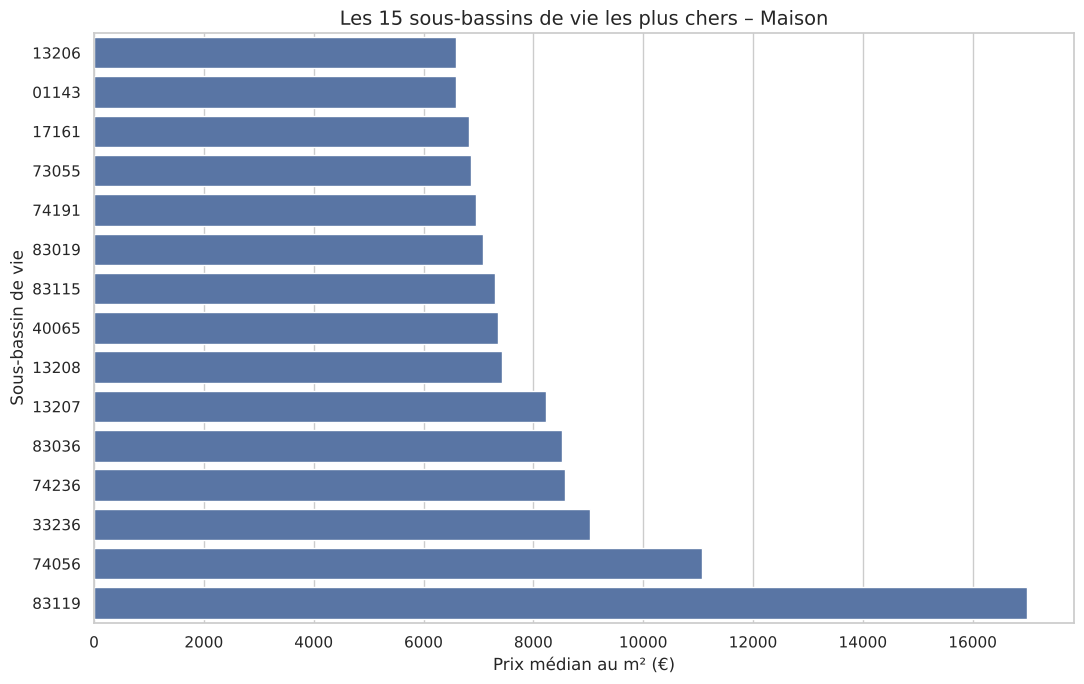

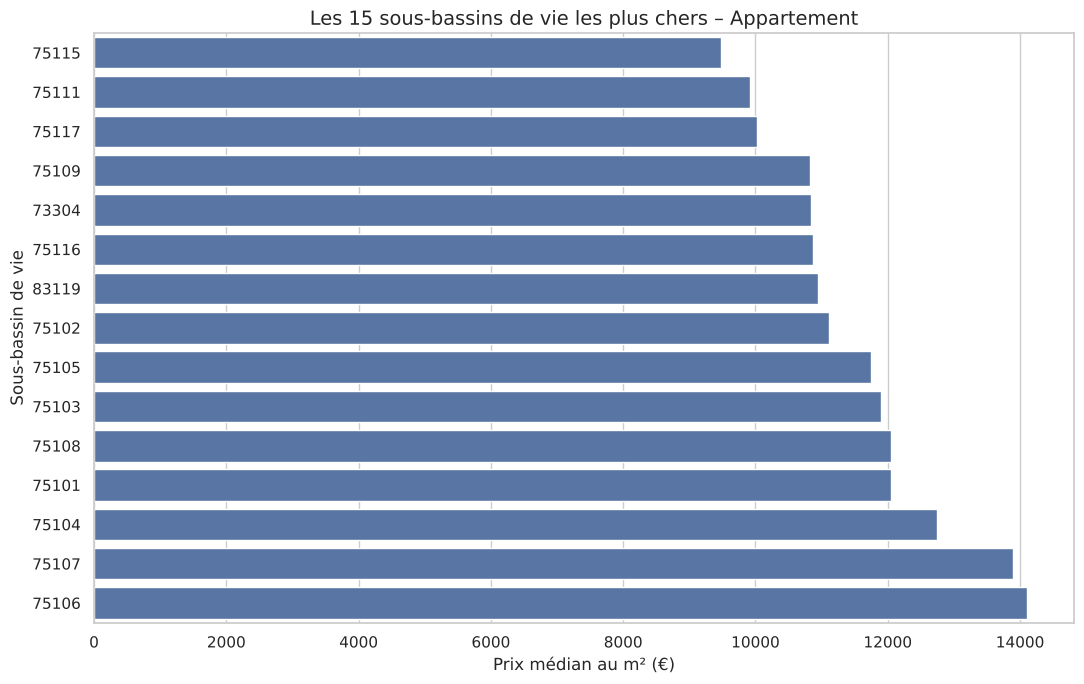

In [13]:
for type_bien in ["maison", "appartement"]:
    donnees = (
        analyse_territoriale[
            analyse_territoriale["type_bien_graphique"] == type_bien
        ]
        .dropna(subset=["prix_median"])
        .nlargest(15, "prix_median")
        .sort_values("prix_median")
    )

    plt.figure(figsize=(11, 7))
    sns.barplot(
        data=donnees,
        x="prix_median",
        y="sous_bassin_graphique"
    )
    plt.title(
        f"Les 15 sous-bassins de vie les plus chers – {type_bien.capitalize()}"
    )
    plt.xlabel("Prix médian au m² (€)")
    plt.ylabel("Sous-bassin de vie")
    plt.tight_layout()
    plt.show()

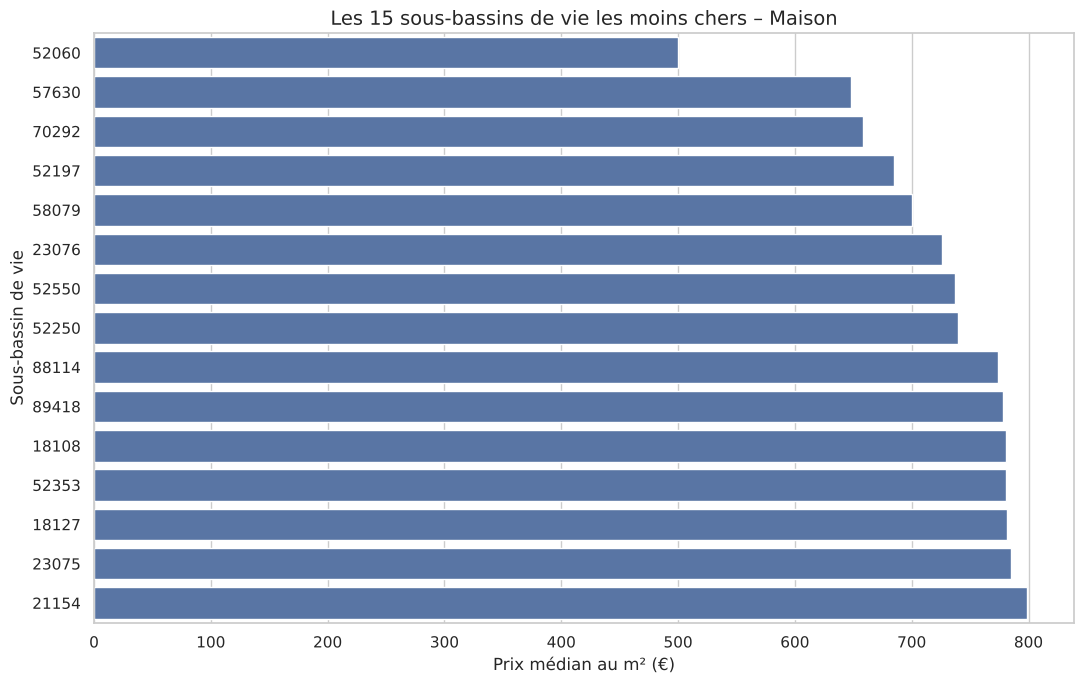

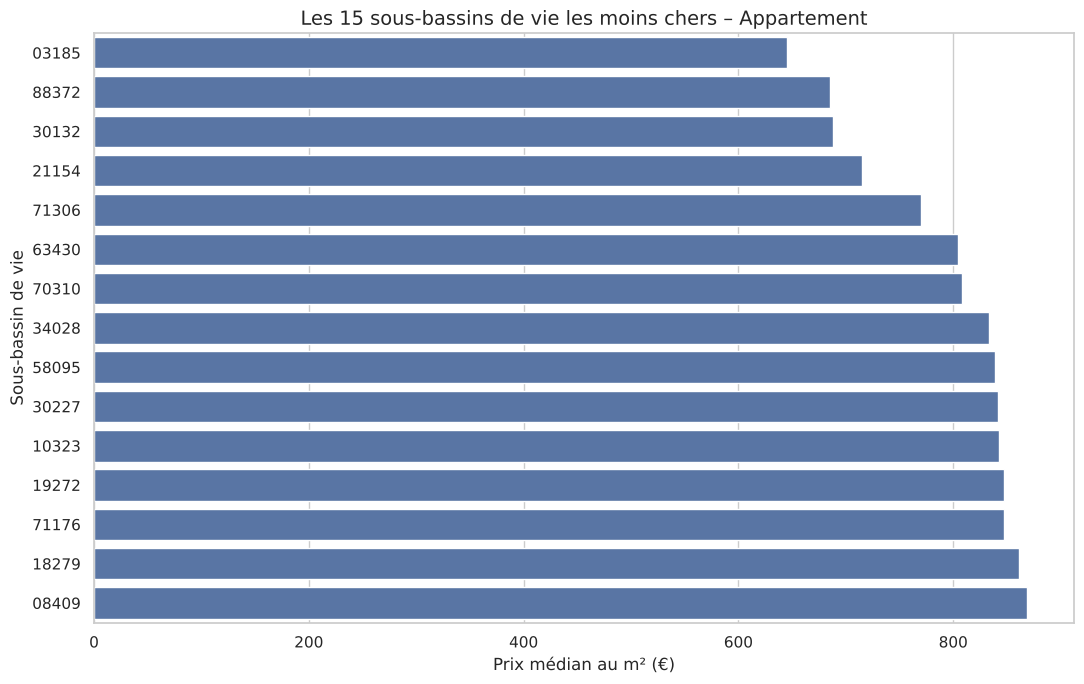

In [14]:
for type_bien in ["maison", "appartement"]:
    donnees = (
        analyse_territoriale[
            analyse_territoriale["type_bien_graphique"] == type_bien
        ]
        .dropna(subset=["prix_median"])
        .nsmallest(15, "prix_median")
        .sort_values("prix_median")
    )

    plt.figure(figsize=(11, 7))
    sns.barplot(
        data=donnees,
        x="prix_median",
        y="sous_bassin_graphique"
    )
    plt.title(
        f"Les 15 sous-bassins de vie les moins chers – {type_bien.capitalize()}"
    )
    plt.xlabel("Prix médian au m² (€)")
    plt.ylabel("Sous-bassin de vie")
    plt.tight_layout()
    plt.show()

### Interprétation – Maisons les plus chères

Les territoires présentant les prix médians les plus élevés pour les maisons sont notamment Saint-Tropez (83119), Chamonix-Mont-Blanc (74056), Lège-Cap-Ferret (33236), Saint-Gervais-les-Bains (74236) et Cavalaire-sur-Mer (83036). Le classement fait aussi ressortir des communes du littoral méditerranéen (Sainte-Maxime, Bormes-les-Mimosas), un territoire alpin (Bozel) et trois arrondissements de Marseille (6e, 7e et 8e). Les prix des maisons sont donc particulièrement élevés dans certains territoires littoraux, touristiques et montagnards.

### Interprétation – Appartements les plus chers

Le classement est largement dominé par les arrondissements de Paris (neuf des dix premiers : 6e, 7e, 4e, 1er, 8e, 3e, 5e, 2e et 16e) ; Saint-Tropez apparaît également. Les caractéristiques territoriales ne semblent pas agir de la même manière selon le type de bien : il reste pertinent de distinguer maisons et appartements.

### Interprétation – Territoires les moins chers

Pour les maisons, les prix médians des territoires les moins chers se situent entre 500 et 800 €/m² ; pour les appartements, entre 650 et 870 €/m². L'écart avec les territoires les plus chers (jusqu'à 16 996 €/m² pour les maisons à Saint-Tropez) traduit une très forte hétérogénéité spatiale du marché.

**Enjeu pour le projet** : la localisation est une dimension majeure de l'explication du prix. Les arrondissements de Paris étant très présents dans ce classement, la qualité de leur densité (section 10) compte pour les territoires les plus chers.

## 9. Analyse de la couverture des indicateurs de sécurité

L'analyse des valeurs manquantes a révélé que plusieurs indicateurs de sécurité présentent exactement le même nombre de valeurs absentes.
Nous cherchons à déterminer si ces absences concernent simultanément les mêmes observations et si elles sont concentrées sur certaines années ou certains sous-bassins de vie.
Cette analyse permettra de mieux comprendre la couverture des données disponibles et d'identifier les éventuelles limites de leur utilisation pour expliquer les prix immobiliers.

In [15]:
indicateurs_securite = [
    "taux3_destructions",
    "taux3_cambriolages",
    "taux3_vols_sans_violence",
    "taux3_vols_violents",
    "taux3_vols_vehicules",
    "taux3_violences_intrafamiliales",
    "taux3_stupefiants",
    "taux3_violences_sexuelles"
]

# Identification des valeurs manquantes
profil_manquants = df_plot[indicateurs_securite].isna()

display(
    profil_manquants.sum().to_frame("Nombre de valeurs manquantes")
)

# Répartition des observations
print(
    "Observations où tous les indicateurs sont manquants :",
    profil_manquants.all(axis=1).sum()
)

print(
    "Observations où au moins un indicateur est manquant :",
    profil_manquants.any(axis=1).sum()
)

print(
    "Observations où aucun indicateur n'est manquant :",
    (~profil_manquants.any(axis=1)).sum()
)

print(
    "Les valeurs manquantes sont-elles simultanées ?",
    profil_manquants.nunique(axis=1).eq(1).all()
)

,Nombre de valeurs manquantes
taux3_destructions,4952
taux3_cambriolages,4952
taux3_vols_sans_violence,4952
taux3_vols_violents,4952
taux3_vols_vehicules,4952
taux3_violences_intrafamiliales,4952
taux3_stupefiants,4952
taux3_violences_sexuelles,4952


Observations où tous les indicateurs sont manquants : 4952
Observations où au moins un indicateur est manquant : 4952
Observations où aucun indicateur n'est manquant : 23498


Les valeurs manquantes sont-elles simultanées ? True


In [16]:
df_manquants = df_plot.copy()

df_manquants["securite_absente"] = (
    df_manquants[indicateurs_securite].isna().all(axis=1)
)

couverture_annuelle = (
    df_manquants
    .groupby("annee_graphique")
    .agg(
        nombre_observations=("securite_absente", "count"),
        observations_sans_securite=("securite_absente", "sum")
    )
    .reset_index()
)

couverture_annuelle["taux_absence_pct"] = (
    couverture_annuelle["observations_sans_securite"]
    / couverture_annuelle["nombre_observations"]
    * 100
)

display(couverture_annuelle.round(2))

,annee_graphique,nombre_observations,observations_sans_securite,taux_absence_pct
0,2015,2460,2460,100.0
1,2016,2492,2492,100.0
2,2017,2522,0,0.0
3,2018,2554,0,0.0
4,2019,2585,0,0.0
5,2020,2637,0,0.0
6,2021,2659,0,0.0
7,2022,2694,0,0.0
8,2023,2642,0,0.0
9,2024,2600,0,0.0


In [17]:
df_manquants["sous_bassin_graphique"] = (
    df_manquants.index.get_level_values("sous_bassin_de_vie")
)

couverture_territoriale = (
    df_manquants
    .groupby("sous_bassin_graphique")
    .agg(
        nombre_observations=("securite_absente", "count"),
        observations_sans_securite=("securite_absente", "sum")
    )
    .reset_index()
)

couverture_territoriale["taux_absence_pct"] = (
    couverture_territoriale["observations_sans_securite"]
    / couverture_territoriale["nombre_observations"]
    * 100
)

display(
    couverture_territoriale
    .sort_values("taux_absence_pct", ascending=False)
    .head(20)
)

,sous_bassin_graphique,nombre_observations,observations_sans_securite,taux_absence_pct
1637,81271,12,3,25.000000
847,43040,17,4,23.529412
538,30212,13,3,23.076923
1498,75119,13,3,23.076923
1803,91405,18,4,22.222222
173,13074,18,4,22.222222
1328,67448,9,2,22.222222
21,01443,18,4,22.222222
413,26325,18,4,22.222222
738,38022,14,3,21.428571


### Interprétation des résultats

Résultats identiques à ceux de la version 3 (le correctif de densité n'a aucun effet sur la délinquance).

- Les huit indicateurs de sécurité présentent **exactement les mêmes valeurs manquantes** : 4 952 observations sur 28 450 (17,4 %) n'ont aucun indicateur ; les 23 498 autres les ont tous.
- Ces absences sont **entièrement concentrées sur 2015 et 2016** (100 % des observations de ces deux années) ; à partir de 2017, tous les indicateurs sont renseignés. Elles sont structurelles (décalage d'un an entre faits et prix, lissage sur trois ans), pas aléatoires.
- Ces absences touchent de nombreux sous-bassins de vie, avec des taux variables selon le nombre d'années présentes.

**Enjeu pour le projet** : il ne faut pas remplacer ces valeurs manquantes par zéro (l'absence de données ne signifie pas l'absence de faits). Deux options : exclure 2015-2016 pour les modèles qui utilisent la délinquance, ou utiliser un modèle qui accepte les valeurs manquantes. Toute imputation doit être ajustée sur le jeu d'entraînement uniquement.

## 10. Densité de population après correctif (nouvelle section)

`densite_population` est une « photo fixe » : une seule valeur par sous-bassin, identique pour toutes les années et pour les deux types de bien (habitants 2024 / superficie). Pour étudier sa distribution, on travaille donc **à la maille sous-bassin**, sans compter chaque sous-bassin plusieurs fois.

Sous-bassins : 1811
Asymétrie (skewness) brute      : 8.35
Asymétrie après log10           : 1.47


,densite_population
count,1811.0
mean,562.0
std,2822.0
min,6.0
25%,40.0
50%,75.0
75%,161.0
max,37873.0


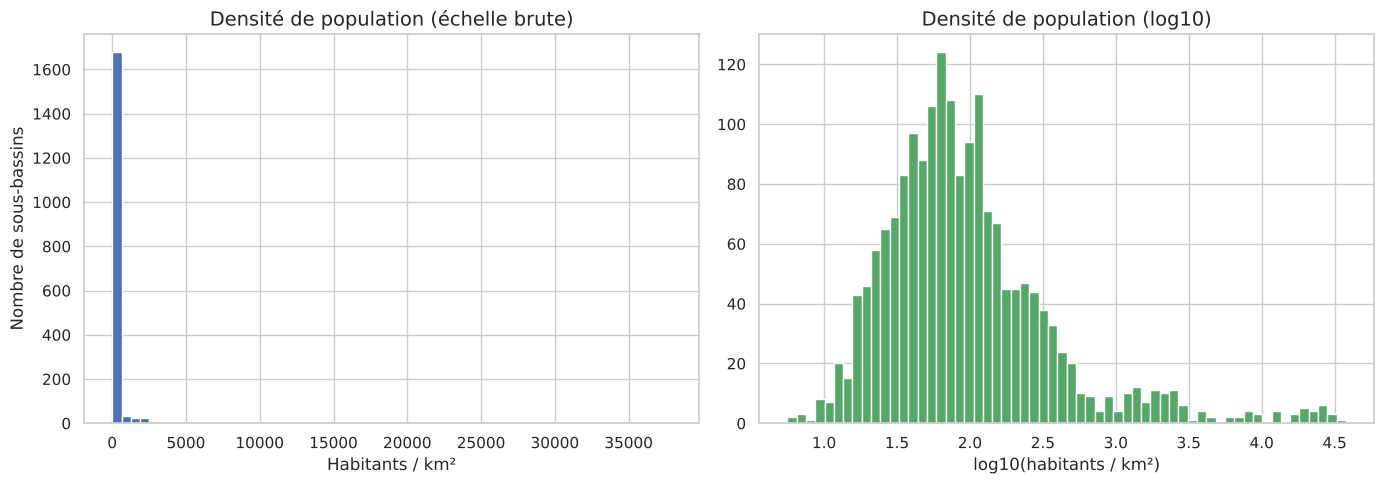

In [18]:
df_plot["sous_bassin_graphique"] = df_plot.index.get_level_values("sous_bassin_de_vie").astype(str)

# Contrôle : une seule valeur de densité par sous-bassin
assert (df_plot.groupby("sous_bassin_graphique")["densite_population"].nunique() == 1).all()

dens = (df_plot.drop_duplicates("sous_bassin_graphique")
        .set_index("sous_bassin_graphique")["densite_population"])

print("Sous-bassins :", len(dens))
print("Asymétrie (skewness) brute      :", round(dens.skew(), 2))
print("Asymétrie après log10           :", round(np.log10(dens).skew(), 2))
display(dens.describe().round(0).to_frame("densite_population"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(dens, bins=60, color="#4C72B0")
axes[0].set_title("Densité de population (échelle brute)")
axes[0].set_xlabel("Habitants / km²")
axes[0].set_ylabel("Nombre de sous-bassins")
axes[1].hist(np.log10(dens), bins=60, color="#55A868")
axes[1].set_title("Densité de population (log10)")
axes[1].set_xlabel("log10(habitants / km²)")
plt.tight_layout()
plt.show()

**Lecture.** La distribution brute est extrêmement asymétrique (skewness 8,4) : la plupart des sous-bassins sont peu denses (médiane 75 hab/km², 75 % sous 161) et une longue queue s'étire jusqu'à 37 873. Après passage au logarithme, la skewness tombe à 1,5 : **la transformation log10 est recommandée** pour `densite_population`, au moins pour les modèles linéaires et les modèles sensibles aux échelles.

,arrondissements,densite_min,densite_mediane,densite_max,densites_distinctes
ville,,,,,
Lyon,9,7106.0,11938.0,18603.0,9
Marseille,16,1119.0,5185.0,22818.0,16
Paris,20,8271.0,24868.0,37873.0,20


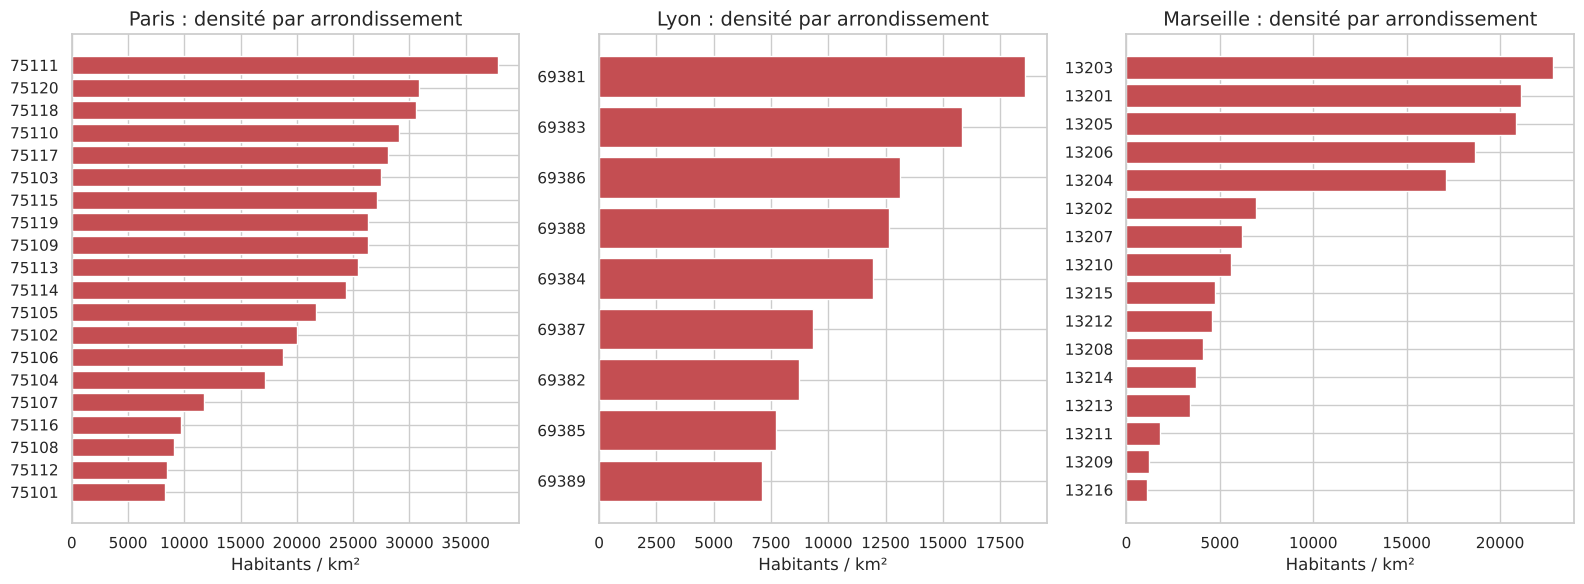

In [19]:
# Les 45 arrondissements de Paris, Lyon et Marseille
motifs = {"Paris": r"^751\d\d$", "Lyon": r"^6938\d$", "Marseille": r"^132\d\d$"}

lignes = []
for ville, motif in motifs.items():
    d = dens[dens.index.str.match(motif)]
    for code_arr, valeur in d.items():
        lignes.append({"ville": ville, "arrondissement": code_arr, "densite": valeur})
arr = pd.DataFrame(lignes)

resume = (arr.groupby("ville")["densite"]
          .agg(arrondissements="count", densite_min="min", densite_mediane="median", densite_max="max",
               densites_distinctes=lambda s: s.round(0).nunique())
          .round(0))
display(resume)

assert resume["arrondissements"].to_dict() == {"Lyon": 9, "Marseille": 16, "Paris": 20}
assert (resume["densites_distinctes"] == resume["arrondissements"]).all()

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, ville in zip(axes, ["Paris", "Lyon", "Marseille"]):
    d = arr[arr["ville"] == ville].sort_values("densite")
    ax.barh(d["arrondissement"], d["densite"], color="#C44E52")
    ax.set_title(f"{ville} : densité par arrondissement")
    ax.set_xlabel("Habitants / km²")
plt.tight_layout()
plt.show()

**Lecture.** Le correctif produit bien **45 densités distinctes** (20 à Paris, 9 à Lyon, 16 à Marseille), alors qu'avec le prorata chaque ville n'avait qu'une seule valeur :

- **Paris** : de 8 271 à 37 873 hab/km² (le 11e est le plus dense, devant le 20e et le 18e).
- **Lyon** : de 7 106 à 18 603 hab/km².
- **Marseille** : de 1 119 (16e) à 22 818 hab/km², soit un écart de 1 à 20 entre arrondissements, que le prorata effaçait complètement.

In [20]:
seuils = [1000, 5000, 10000]
est_arr = dens.index.isin(arr["arrondissement"])

tableau = pd.DataFrame({
    "sous-bassins au-dessus du seuil": [(dens > s).sum() for s in seuils],
    "dont arrondissements":            [((dens > s) & est_arr).sum() for s in seuils],
}, index=[f"> {s} hab/km²" for s in seuils])
display(tableau)

print("Densité maximale hors arrondissements :", round(dens[~est_arr].max()),
      "(sous-bassin", dens[~est_arr].idxmax() + ")")
print("Arrondissements au-dessus de 10 000 hab/km² :", int((dens[est_arr] > 10000).sum()), "sur 45")

,sous-bassins au-dessus du seuil,dont arrondissements
> 1000 hab/km²,112,45
> 5000 hab/km²,37,37
> 10000 hab/km²,26,26


Densité maximale hors arrondissements : 3889 (sous-bassin 56121_1)
Arrondissements au-dessus de 10 000 hab/km² : 26 sur 45


**Lecture.** Tous les sous-bassins au-dessus de 5 000 hab/km² sont des arrondissements de Paris, Lyon ou Marseille. Hors arrondissements, la densité maximale est d'environ 3 900 hab/km². Les 45 arrondissements forment donc un groupe à part, nettement séparé du reste de la distribution : ils exercent un fort effet de levier sur un modèle linéaire non transformé. La transformation log atténue ce phénomène.

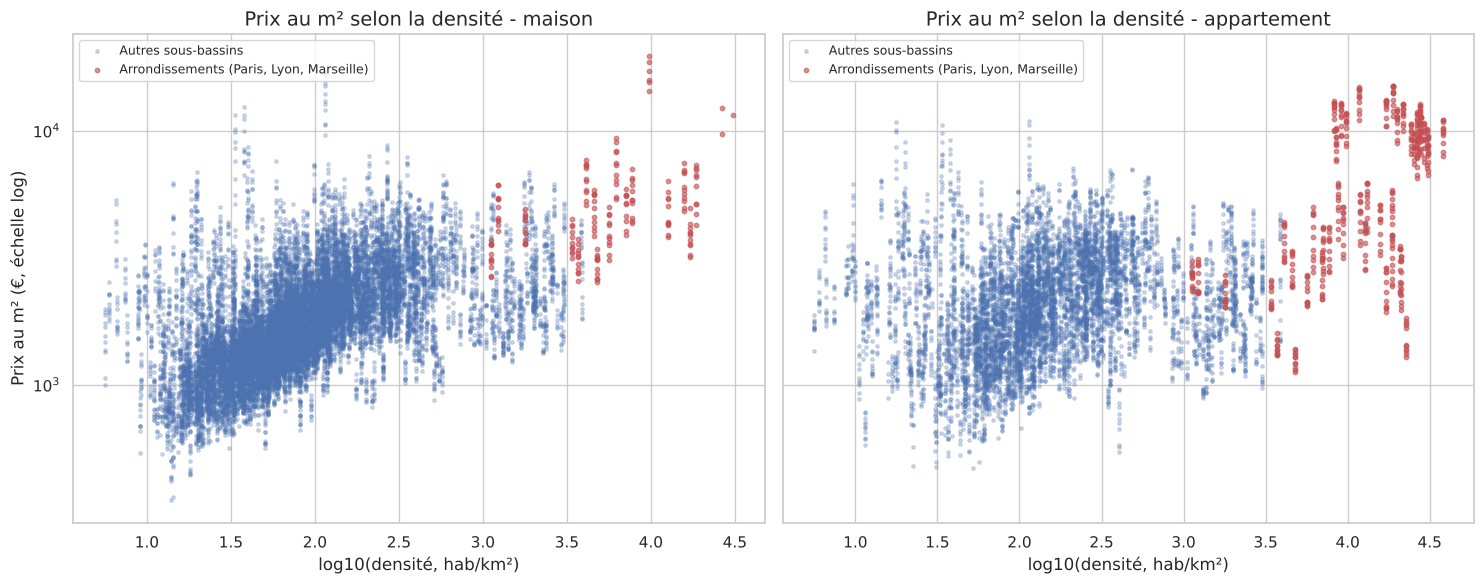

Corrélation de Spearman densité / prix :
  maison       0.62
  appartement  0.36


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, type_bien in zip(axes, ["maison", "appartement"]):
    sous = df_plot[df_plot["type_bien_graphique"] == type_bien].dropna(subset=["prix"])
    est_arr_ligne = sous["sous_bassin_graphique"].isin(arr["arrondissement"])
    ax.scatter(np.log10(sous.loc[~est_arr_ligne, "densite_population"]),
               sous.loc[~est_arr_ligne, "prix"], s=6, alpha=0.25, label="Autres sous-bassins")
    ax.scatter(np.log10(sous.loc[est_arr_ligne, "densite_population"]),
               sous.loc[est_arr_ligne, "prix"], s=10, alpha=0.6, color="#C44E52", label="Arrondissements (Paris, Lyon, Marseille)")
    ax.set_yscale("log")
    ax.set_title(f"Prix au m² selon la densité - {type_bien}")
    ax.set_xlabel("log10(densité, hab/km²)")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Prix au m² (€, échelle log)")
plt.tight_layout()
plt.show()

print("Corrélation de Spearman densité / prix :")
for type_bien in ["maison", "appartement"]:
    sous = df_plot[df_plot["type_bien_graphique"] == type_bien]
    print(f"  {type_bien:12s}", round(sous[["densite_population", "prix"]].corr(method="spearman").iloc[0, 1], 2))

**Lecture.** La densité est positivement liée au prix (corrélation de Spearman : **0,62 pour les maisons, 0,36 pour les appartements**). La relation est nettement plus nette pour les maisons ; pour les appartements, la dispersion des prix reste forte à densité comparable. La densité n'est donc pas un substitut du prix : elle apporte une information complémentaire.

**Conséquences pour la modélisation** :
1. appliquer `log10` à `densite_population` (asymétrie 8,4 → 1,5) ;
2. garder la distinction maison / appartement (l'effet de la densité diffère selon le segment) ;
3. surveiller l'effet des 45 arrondissements sur l'ajustement du modèle (analyse de sensibilité avec / sans arrondissements).

## 11. Revue des variables explicatives (nouvelle section)

Cette section complète les corrélations de la section 6 (limitées à 12 colonnes pour les maisons) en examinant **l'ensemble des variables explicatives** (34, hors indicatrice `maison`) : asymétrie, colinéarité et lien avec le prix, pour les deux segments.

In [22]:
# Variables explicatives : toute la table sauf la cible (prix), n_ventes (fuite), l'année et l'indicatrice maison
hors_features = ["prix", "n_ventes", "annee", "maison", "annee_graphique"]
features = [c for c in df.columns if c not in hors_features]
print("Nombre de variables explicatives :", len(features))

asymetrie = df[features].skew().sort_values(key=abs, ascending=False).round(1)
candidats_log = asymetrie[asymetrie.abs() > 2]
print(f"\nVariables avec |skewness| > 2 ({len(candidats_log)}) : candidates à une transformation log")
display(candidats_log.to_frame("skewness"))

Nombre de variables explicatives : 34

Variables avec |skewness| > 2 (17) : candidates à une transformation log


,skewness
nb_ventes_n1,33.8
taux3_vols_sans_violence,19.4
taux_equip_transports,14.7
taux3_vols_violents,14.2
taux3_stupefiants,13.6
densite_population,9.0
taux_equip_commerces,6.6
taux_equip_tourisme,5.5
taux_equip_services,5.2
taux3_vols_vehicules,5.0


**Lecture.** 17 variables sur 34 ont une asymétrie supérieure à 2 en valeur absolue. Les plus marquées sont `nb_ventes_n1` (34), `taux3_vols_sans_violence` (19), `taux_equip_transports` (15), `taux3_vols_violents` (14), `taux3_stupefiants` (14) et `densite_population` (9). Pour ces variables, une transformation `log1p` (les valeurs nulles étant possibles) est à envisager pour les modèles linéaires ; les modèles à base d'arbres n'en ont pas besoin.

In [23]:
corr_spearman = df[features].corr(method="spearman").abs()
paires = [(a, b, round(corr_spearman.loc[a, b], 2))
          for i, a in enumerate(corr_spearman.columns)
          for b in corr_spearman.columns[i + 1:]
          if corr_spearman.loc[a, b] > 0.7]
paires = pd.DataFrame(sorted(paires, key=lambda x: -x[2]), columns=["variable A", "variable B", "|Spearman|"])
print("Paires de variables explicatives fortement corrélées (|Spearman| > 0,7) :")
display(paires)

Paires de variables explicatives fortement corrélées (|Spearman| > 0,7) :


,variable A,variable B,|Spearman|
0,part_moins40m2,part_suroccupes,0.88
1,part_sans_voiture,part_parking,0.84
2,taux3_vols_sans_violence,taux3_destructions,0.78
3,taux_equip_sports,densite_population,0.76
4,taux_equip_tourisme,part_rsec,0.76
5,part_apparts,part_moins40m2,0.76
6,taux3_violences_intrafamiliales,taux3_violences_sexuelles,0.75
7,part_apparts,part_suroccupes,0.74
8,taux3_vols_sans_violence,part_moins40m2,0.70


**Lecture.** Le risque de colinéarité est limité : seules deux paires dépassent 0,8 (`part_moins40m2` / `part_suroccupes` : 0,88 ; `part_sans_voiture` / `part_parking` : 0,84) et neuf paires dépassent 0,7, dont `densite_population` / `taux_equip_sports` (0,76). Pour les modèles linéaires régularisés ou à base d'arbres, ce niveau est acceptable ; pour un modèle linéaire simple, on pourra retirer une variable dans chacune des deux paires les plus corrélées.

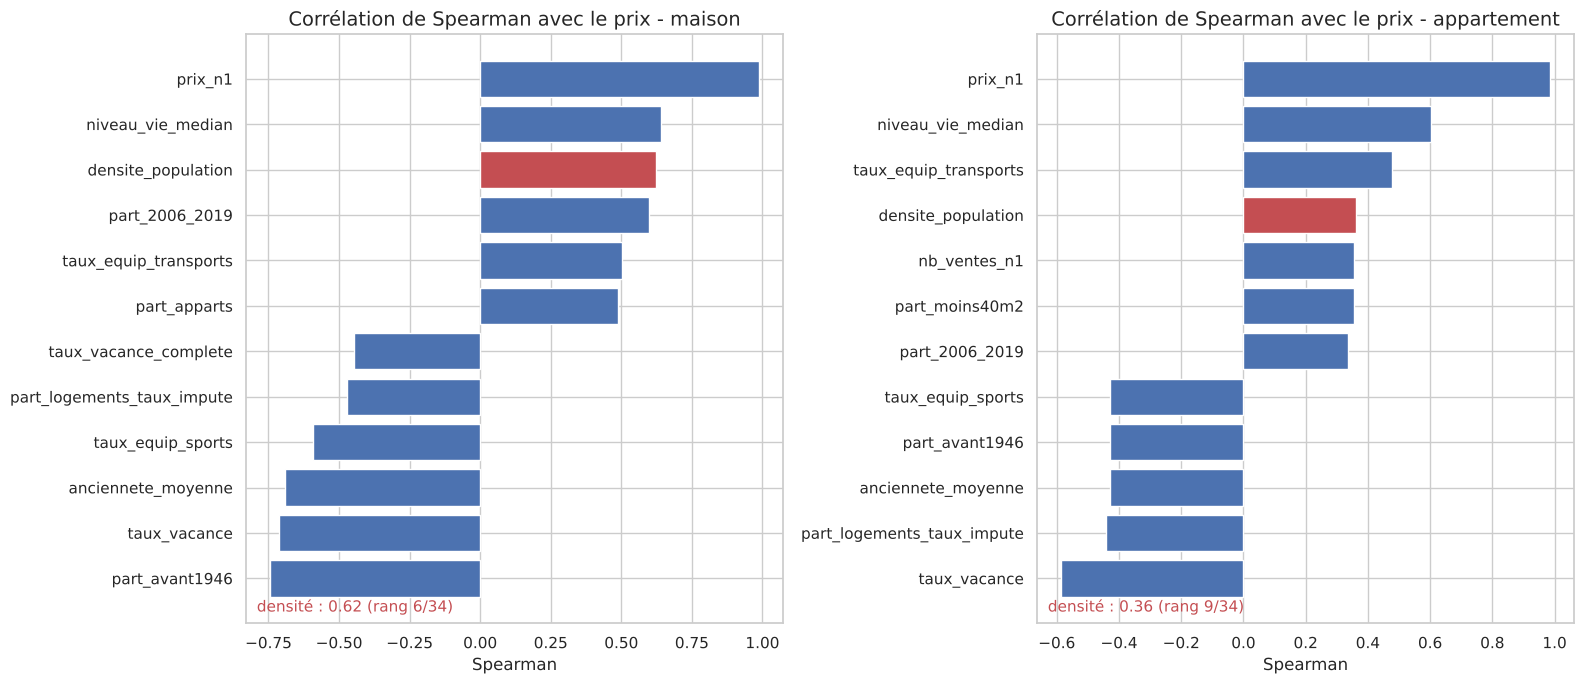

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, type_bien in zip(axes, ["maison", "appartement"]):
    sous = df[df.index.get_level_values("type_bien") == type_bien]
    c = sous[features].corrwith(sous["prix"], method="spearman")
    top = c.reindex(c.abs().sort_values(ascending=False).head(12).index).sort_values()
    couleurs = ["#C44E52" if nom == "densite_population" else "#4C72B0" for nom in top.index]
    ax.barh(top.index, top.values, color=couleurs)
    ax.set_title(f"Corrélation de Spearman avec le prix - {type_bien}")
    ax.set_xlabel("Spearman")
    rang = int(c.abs().rank(ascending=False)["densite_population"])
    ax.text(0.02, 0.02, f"densité : {c['densite_population']:.2f} (rang {rang}/34)",
            transform=ax.transAxes, color="#C44E52", fontsize=11)
plt.tight_layout()
plt.show()

**Lecture.**
- **`prix_n1` domine** : la corrélation avec le prix est de 0,99 (maisons) et 0,98 (appartements). Un modèle qui reproduit simplement le prix de l'année précédente sera très difficile à battre ; les variables territoriales devront donc expliquer l'**évolution** ou les **écarts résiduels** plutôt que le niveau.
- Pour les **maisons**, les variables les plus liées au prix sont ensuite l'ancienneté du parc (`part_avant1946` -0,74, `anciennete_moyenne` -0,69), `taux_vacance` (-0,71), `niveau_vie_median` (0,64) et **`densite_population` (0,62)**.
- Pour les **appartements**, ce sont `niveau_vie_median` (0,60), `taux_vacance` (-0,58) et `taux_equip_transports` (0,48) ; la densité (0,36) est moins discriminante.

## 12. Synthèse et recommandations

**Intégrité de la table**
- 28 450 lignes × 38 colonnes, index à 3 niveaux unique, 1 811 sous-bassins, 2015-2025, 19 559 lignes maisons et 8 891 appartements.
- Sections 1 à 4 et 6 à 9 : résultats **identiques** à la version 3 (le correctif de densité n'affecte que `densite_population`).

**Effet du correctif de densité**
- 45 arrondissements avec 45 densités distinctes (Paris 8 271-37 873 ; Lyon 7 106-18 603 ; Marseille 1 119-22 818), contre une seule valeur par ville auparavant.
- Seule la queue haute de la distribution change : quartiles inchangés, maximum de 20 036 à 37 873.
- Tous les sous-bassins au-dessus de 5 000 hab/km² sont des arrondissements.

**Recommandations pour la modélisation**
1. Appliquer `log10` à `densite_population` (asymétrie 8,4 → 1,5), et `log1p` aux autres variables très asymétriques pour les modèles linéaires.
2. Conserver la distinction maison / appartement.
3. Traiter les valeurs manquantes de délinquance (2015-2016) sans les remplacer par zéro : exclusion de ces années pour les modèles concernés ou modèle tolérant les manquants ; imputation, si elle a lieu, ajustée sur l'entraînement seul.
4. Prendre `prix_n1` comme référence : toute variable territoriale doit être jugée par son gain par rapport à cette baseline.
5. Réaliser une analyse de sensibilité avec et sans les 45 arrondissements.
6. Relancer les notebooks de modélisation et l'audit complémentaire avec cette table, et comparer les métriques avant / après.

**Points à clarifier avec l'équipe**
- `part_menages_couverts` dépasse 100 % dans 118 sous-bassins (maximum 119 %) : définitions Filosofi / recensement légèrement différentes.
- Les grands sous-bassins scindés (par exemple `75056_1`, `69123_1`) ont des volumes de ventes très élevés (jusqu'à 70 042) : vérifier leur cohérence avec les arrondissements correspondants.